# INTRODUCTION, METRIC, DATASETS

This project analyzes three data sets across Allegheny County. The metrics for our arguements ae based on sterotypes of computer science students. Naturally, they would not go outside (lack green space), not shower (less availability/use of water), and probably live somewhere filthy (such as a place with regular dumping). All three of our datasets represent a respective metric, 311 calls pertaining to dumping, neighborhoods lacking green space, and places that use and waste less water (because that likely correlates to water availability). 

## Getting Started

In [42]:
import pandas as pd
import numpy as np

## Pittsburgh 311 Data

looking for most amount of 311 call complaining about illegal dumping.

### Loading the CSV

Let's load the CSV!
Due to some issues that I encountered, I had to specify the type for a couple of the column.


In [43]:
dtype_311 = {
    "street": np.str_,
    "street_id": np.str_,
    "neighborhood": np.str_,
}

df_311 = pd.read_csv("pittsburgh_311_data/data.csv", dtype=dtype_311, parse_dates=True)

df_311

,_id,case_number,status,case_owner,subject,subject_code,legacy_subject,created_date_et,created_date_utc,last_modified_date_et,...,city,neighborhood,census_tract,council_district,ward,police_zone,latitude,longitude,geo_accuracy,unique_id
0,1,99-00082323,Closed,311,ADA Parking,ADAPRKREQ,Handicapped Parking Application,2016-08-31T10:13:00.000,2016-08-31T14:13:00.000,2026-08-04T02:18:10.000,...,CARNEGIE,Lincoln-Lemington-Belmar,NaN,D9,13.0,5.0,NaN,NaN,EXACT,99-00082323-16
1,2,99-00306710,Closed,NaN,ADA Parking,ADAPRKREQ,NaN,2021-04-09T08:39:00.000,2021-04-09T12:39:00.000,2026-08-03T00:11:25.000,...,NaN,East Allegheny,5632.02,D1,23.0,1.0,40.45246,-79.99877,EXACT,99-00306710-21
2,3,99-00558811,Closed,NaN,ADA Parking,ADAPRKREQ,NaN,2018-07-19T16:51:00.000,2018-07-19T20:51:00.000,2026-08-02T23:52:17.000,...,Pittsburgh,Squirrel Hill South,9805.00,D5,14.0,4.0,40.43491,-79.94663,EXACT,99-00558811-18
3,4,99-00646565,Closed,DOMI - Traffic,ADA Parking,ADAPRKREQ,"Handicap Parking Signs, Removal",2017-10-03T15:02:00.000,2017-10-03T19:02:00.000,2026-08-02T23:15:48.000,...,Pittsburgh,NaN,NaN,NaN,NaN,NaN,NaN,NaN,EXACT,99-00646565-17
4,5,99-00645467,Closed,DOMI - Traffic,ADA Parking,ADAPRKREQ,"Handicap Parking Signs, Removal",2017-10-09T11:14:00.000,2017-10-09T15:14:00.000,2026-08-04T02:19:46.000,...,Pittsburgh,NaN,NaN,NaN,NaN,NaN,NaN,NaN,EXACT,99-00645467-17
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
982308,1095209,26-00116433,Open (Duplicate),DPW ES Enforcement,Refuse or Recycling Violations,REFUSEVIOL,NaN,2026-11-10T17:12:09.000,2026-11-10T22:12:09.000,2026-11-10T17:12:11.000,...,PITTSBURGH,Beechview,1916.00,D4,NaN,6.0,40.41177,-80.01351,EXACT,26-00116433-26
982309,1095214,26-00116322,Open,Animal Care and Control,Rodent Control,RDNTCTRL,NaN,2026-11-10T13:04:56.000,2026-11-10T18:04:56.000,2026-11-10T13:04:58.000,...,PITTSBURGH,Homewood North,1307.00,D9,NaN,5.0,40.46000,-79.89000,APPROXIMATE,26-00116322-26
982310,1095234,26-00116420,Open,DPW Environmental Services,Missed Pick Up,MSSDPICKUP,NaN,2026-11-10T16:44:25.000,2026-11-10T21:44:25.000,2026-11-10T16:44:27.000,...,PITTSBURGH,Bedford Dwellings,509.00,D6,NaN,2.0,40.45000,-79.97000,APPROXIMATE,26-00116420-26
982311,1095253,26-00116436,Open,DPW Environmental Services,Recycling/Refuse/Blue Bin Questions,RECREFQST,NaN,2026-11-10T17:17:31.000,2026-11-10T22:17:31.000,2026-11-10T17:17:33.000,...,PITTSBURGH,Brookline,3206.00,D4,NaN,6.0,40.40000,-80.01000,APPROXIMATE,26-00116436-26


### Pittsburgh Only

Now that we have our dataframe, we want to ensure that we are only looking at data from Pittsburgh!

This can be done pretty quickly and easily with the syntax below!

In [44]:
# Pittsburgh Only

df_311 = df_311[df_311["city"] == "Pittsburgh"]
df_311

,_id,case_number,status,case_owner,subject,subject_code,legacy_subject,created_date_et,created_date_utc,last_modified_date_et,...,city,neighborhood,census_tract,council_district,ward,police_zone,latitude,longitude,geo_accuracy,unique_id
2,3,99-00558811,Closed,NaN,ADA Parking,ADAPRKREQ,NaN,2018-07-19T16:51:00.000,2018-07-19T20:51:00.000,2026-08-02T23:52:17.000,...,Pittsburgh,Squirrel Hill South,9805.0,D5,14.0,4.0,40.43491,-79.94663,EXACT,99-00558811-18
3,4,99-00646565,Closed,DOMI - Traffic,ADA Parking,ADAPRKREQ,"Handicap Parking Signs, Removal",2017-10-03T15:02:00.000,2017-10-03T19:02:00.000,2026-08-02T23:15:48.000,...,Pittsburgh,NaN,NaN,NaN,NaN,NaN,NaN,NaN,EXACT,99-00646565-17
4,5,99-00645467,Closed,DOMI - Traffic,ADA Parking,ADAPRKREQ,"Handicap Parking Signs, Removal",2017-10-09T11:14:00.000,2017-10-09T15:14:00.000,2026-08-04T02:19:46.000,...,Pittsburgh,NaN,NaN,NaN,NaN,NaN,NaN,NaN,EXACT,99-00645467-17
7,8,99-00946148,Closed,NaN,ADA Parking,ADAPRKREQ,NaN,2016-02-02T14:34:00.000,2016-02-02T19:34:00.000,2026-08-03T00:11:32.000,...,Pittsburgh,Lincoln-Lemington-Belmar,1203.0,D9,12.0,5.0,40.46702,-79.90436,EXACT,99-00946148-16
8,9,99-00726156,Closed,DOMI - Traffic,ADA Parking,ADAPRKREQ,"Handicap Parking Signs, Removal",2016-05-26T00:24:00.000,2016-05-26T04:24:00.000,2026-08-03T02:38:09.000,...,Pittsburgh,NaN,NaN,NaN,NaN,NaN,NaN,NaN,EXACT,99-00726156-16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
918192,918193,99-00219156,Closed,"Permits, Licenses and Inspections",Zoning Issues,ZONINGISSUE,Zoning Issue,2022-06-14T12:06:00.000,2022-06-14T16:06:00.000,2026-08-03T01:15:44.000,...,Pittsburgh,Fairywood,5630.0,D2,28.0,6.0,40.45000,-80.08000,APPROXIMATE,99-00219156-22
918193,918194,99-00162954,Closed,"Permits, Licenses and Inspections",Zoning Issues,ZONINGISSUE,Zoning Issue,2023-11-16T13:35:00.000,2023-11-16T18:35:00.000,2026-08-04T03:07:45.000,...,Pittsburgh,Central Oakland,405.0,D3,4.0,4.0,40.44000,-79.95000,APPROXIMATE,99-00162954-23
918194,918195,99-00064184,Closed,"Permits, Licenses and Inspections",Zoning Issues,ZONINGISSUE,Zoning Issue,2024-09-24T10:36:00.000,2024-09-24T14:36:00.000,2026-08-03T02:01:59.000,...,Pittsburgh,Spring Hill-City View,2620.0,D1,24.0,1.0,40.46000,-79.99000,APPROXIMATE,99-00064184-24
918198,918199,99-00295233,Closed,"Permits, Licenses and Inspections",Zoning Issues,ZONINGISSUE,Zoning Issue,2021-03-14T21:37:00.000,2021-03-15T01:37:00.000,2026-08-04T23:34:53.000,...,Pittsburgh,Central Oakland,405.0,D3,4.0,4.0,40.44000,-79.95000,APPROXIMATE,99-00295233-21


### Illegal Dumping

Now we just have to look for illegal dumping complaints!

This can be dont by filtering by the subject code "ILLEDUMP".

The dataset did not come with a list of these codes, but it did have both the subject code and a human readable subject so we were able to figure out a subject code for illegal dumping quite quickly!

In [45]:
df_311 = df_311[df_311["subject_code"] == "ILLEDUMP"]

df_311

,_id,case_number,status,case_owner,subject,subject_code,legacy_subject,created_date_et,created_date_utc,last_modified_date_et,...,city,neighborhood,census_tract,council_district,ward,police_zone,latitude,longitude,geo_accuracy,unique_id
218876,218877,99-00903263,Closed,NaN,Illegal Dumping,ILLEDUMP,NaN,2016-07-05T11:10:00.000,2016-07-05T15:10:00.000,2026-08-03T01:40:04.000,...,Pittsburgh,Brookline,1918.00,D4,19.0,6.0,40.39,-80.01,APPROXIMATE,99-00903263-16
218877,218878,99-00834159,Closed,NaN,Illegal Dumping,ILLEDUMP,NaN,2015-12-04T00:07:00.000,2015-12-04T05:07:00.000,2026-08-03T22:56:47.000,...,Pittsburgh,Lincoln Place,3102.00,D5,31.0,4.0,40.37,-79.92,APPROXIMATE,99-00834159-15
218881,218882,99-00825678,Closed,DOMI - Permits,Illegal Dumping,ILLEDUMP,Illegal Dumping,2018-09-21T14:39:00.000,2018-09-21T18:39:00.000,2026-08-04T23:59:36.000,...,Pittsburgh,South Side Flats,1609.00,D3,16.0,3.0,40.43,-79.97,APPROXIMATE,99-00825678-18
218888,218889,55-00048018,Open,DOMI - Permits,Illegal Dumping,ILLEDUMP,Illegal Dumping,2021-05-31T19:02:00.000,2021-05-31T23:02:00.000,2026-08-05T02:15:38.000,...,Pittsburgh,NaN,NaN,NaN,NaN,NaN,NaN,NaN,APPROXIMATE,55-00048018-21
218891,218892,99-00972320,Closed,NaN,Illegal Dumping,ILLEDUMP,NaN,2016-08-19T16:41:00.000,2016-08-19T20:41:00.000,2026-08-03T00:11:29.000,...,Pittsburgh,East Allegheny,5632.02,D1,23.0,1.0,40.45,-80.00,APPROXIMATE,99-00972320-16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
226752,226753,99-00892006,Closed,DPW - Park Maintenance,Illegal Dumping,ILLEDUMP,Illegal Dumping,2022-12-05T11:54:00.000,2022-12-05T16:54:00.000,2026-08-04T02:24:31.000,...,Pittsburgh,Knoxville,3001.00,D3,30.0,3.0,40.42,-79.99,APPROXIMATE,99-00892006-22
226753,226754,99-00857760,Closed,DOMI - Permits,Illegal Dumping,ILLEDUMP,Illegal Dumping,2020-10-16T18:38:00.000,2020-10-16T22:38:00.000,2026-08-04T02:28:07.000,...,Pittsburgh,Knoxville,3001.00,D3,30.0,3.0,40.42,-80.00,APPROXIMATE,99-00857760-20
226757,226758,99-00863424,Closed,DOMI - Permits,Illegal Dumping,ILLEDUMP,Illegal Dumping,2020-11-19T11:28:00.000,2020-11-19T16:28:00.000,2026-08-03T01:22:24.000,...,Pittsburgh,Beltzhoover,5624.00,D4,18.0,3.0,40.42,-80.00,APPROXIMATE,99-00863424-20
226760,226761,99-00857772,Closed,DOMI - Permits,Illegal Dumping,ILLEDUMP,Illegal Dumping,2020-10-26T10:26:00.000,2020-10-26T14:26:00.000,2026-08-05T00:49:20.000,...,Pittsburgh,Sheraden,5625.00,D2,20.0,6.0,40.45,-80.05,APPROXIMATE,99-00857772-20


### Summing It Up!

No, like in the literal meaining! We need to know how many times a neighborhood appears in this dataset. We will use "value_counts" for this!

In [46]:
val_count_311 = df_311["neighborhood"].value_counts()
val_count_311

neighborhood
South Side Slopes    205
Hazelwood            161
South Side Flats     123
Garfield             103
Larimer              100
                    ... 
Glen Hazel             3
Windgap                3
Summer Hill            2
Regent Square          1
Ridgemont              1
Name: count, Length: 89, dtype: int64

### Plotting

Let's just plot the data, it's pretty simple here thanks to Pandas. (THANK YOU PANDAS!)

<Axes: xlabel='Neighborhood', ylabel='# of Illegal Dumping 311 Complaints'>

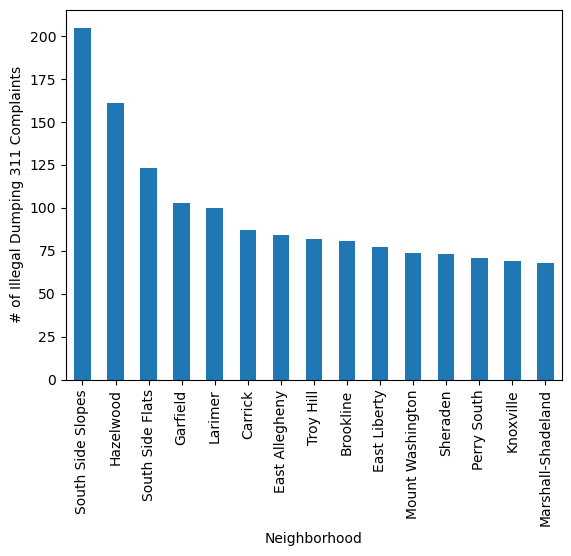

In [47]:
val_count_311.head(15).plot(kind="bar", xlabel="Neighborhood", ylabel="# of Illegal Dumping 311 Complaints")

## Green Spaces

### What are we looking for?

We are looking for the areas with the least amount of green space. CS majors don't "touch grass."

### Load the CSV

Let's load the CSV!

In [18]:
df_g = pd.read_csv("green_spaces/data.csv")
df_g

,Responsibility_Parks or Operations,Facility,Division,Total Acreage,Maintainable Acreage,Shelter,Rec Center,Senior Center,Pool,Spray Pool,...,Grandstand,Control Link for Basketball Courts,Control Link for Tennis Court,Control Linkl for Hockey Court,Dek Hockey Court,Dog Park,Spray Park,Ownership of Facility,Benches,Tables
0,Operations,Bates St Triangle,3.0,0.20,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,No,No,No,NaN,NaN,NaN,NaN,NaN,NaN
1,Operations,Baum Negley Triangle,2.0,0.20,NaN,NaN,0.0,0.0,NaN,NaN,...,NaN,No,No,No,NaN,NaN,NaN,NaN,0.0,0.0
2,Operations,Bedford Strip,3.0,0.30,NaN,NaN,0.0,0.0,NaN,NaN,...,NaN,No,No,No,NaN,NaN,NaN,NaN,0.0,0.0
3,Operations,Beechview Monument,5.0,0.10,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,No,No,No,NaN,NaN,NaN,NaN,2.0,NaN
4,Operations,Brookline Monument,4.0,0.10,NaN,NaN,0.0,0.0,NaN,NaN,...,NaN,No,No,No,NaN,NaN,NaN,NaN,0.0,0.0
5,Operations,Craft Triangle,3.0,0.10,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,No,No,No,NaN,NaN,NaN,NaN,NaN,NaN
6,Operations,Crosstown,6.0,1.20,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,No,No,No,NaN,NaN,NaN,NaN,NaN,NaN
7,Operations,East Liberty Strip,2.0,2.00,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,No,No,No,NaN,NaN,NaN,NaN,NaN,NaN
8,Operations,Edgerton Circle,3.0,0.01,NaN,NaN,0.0,0.0,NaN,NaN,...,NaN,No,No,No,NaN,NaN,NaN,NaN,0.0,0.0
9,Operations,Fort Duquesne Blvd Strip,6.0,NaN,NaN,NaN,0.0,0.0,NaN,NaN,...,NaN,No,No,No,NaN,NaN,NaN,NaN,0.0,0.0


### One, Two, Three

Now we need to count how many times a neighborhood appears in this dataset. As before, we are going to use "value_counts" for this!

In [19]:
val_counts_g = df_g["Neighborhood"].value_counts()
val_counts_g

Neighborhood
East Liberty                 6
Point Breeze                 5
Central Business District    4
Central Oakland              3
South Oakland                2
Point Breeze North           2
Squirrel Hill South          2
Swisshelm Park               2
Beechview                    1
Crawford Roberts             1
Brookline                    1
North Oakland                1
Polish Hill                  1
Regent Square                1
Sheraden                     1
Name: count, dtype: int64

### Evil Plot

The plot isn't actually evil.

We will just plot this the same way as the 311 data but with different arguments and not calling "head."

<Axes: xlabel='Neighborhood', ylabel='# Green Spaces'>

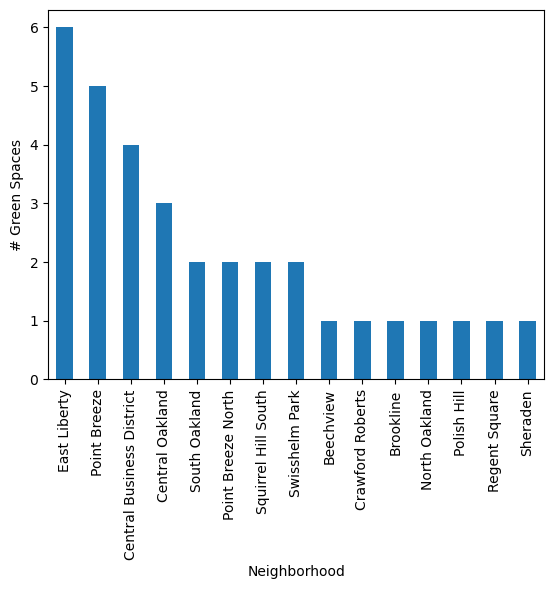

In [20]:
val_counts_g.plot(kind="bar", ylabel="# Green Spaces")

## Water

### Water is the essence of a shower!

CS majors have a stereotype of not showwering. Showering requires water, so we are looking for places where water is less readily available.

(also, I know you're dehydrated, go drink some water)

### Let's load the CSV

Same as the first two!

In [22]:
df_w = pd.read_csv("water/data.csv")
df_w

,id,name,control_type,feature_type,inactive,make,image,neighborhood,council_district,ward,tract,public_works_division,pli_division,police_zone,fire_zone,latitude,longitude
0,2004439323,Mellon Square - Cascade Fountain,On/Off,Decorative,False,Water Odyssey,https://storage.googleapis.com/pghpa_open_data...,Central Business District,1,2,42003020100,1,2,2,1-4,40.440814,-79.997823
1,320166810,Ammon Park - Drinking Fountain 01,On/Off,Drinking Fountain,False,Regular Fountain,NaN,Bedford Dwellings,6,5,42003050900,3,5,2,2-5,40.449287,-79.977762
2,2070285666,Kennard Park - Drinking Fountain 04,NaN,Drinking Fountain,False,NaN,NaN,Terrace Village,6,5,42003051000,3,5,2,2-10,40.442990,-79.972578
3,1086485662,Mellon Park - Waves Spray,On/Off,Spray,False,NaN,https://storage.googleapis.com/pghpa_open_data...,Shadyside,8,7,42003070800,2,7,4,3-13,40.454059,-79.915652
4,192771028,Mellon Park - Dump Buckets,On/Off,Spray,False,NaN,https://storage.googleapis.com/pghpa_open_data...,Shadyside,8,7,42003070800,2,7,4,3-13,40.453945,-79.915680
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283,1948209895,Schenley Park - Drinking Fountain 01_RET 25,On/Off,Drinking Fountain,True,Regular Fountain,https://storage.googleapis.com/pghpa_open_data...,Squirrel Hill South,5,14,42003980500,3,14,4,2-8,40.440600,-79.948481
284,273620901,Schenley Park - Drinking Fountain 04,On/Off,Drinking Fountain,False,NaN,https://storage.googleapis.com/pghpa_open_data...,Squirrel Hill South,5,14,42003980500,3,14,4,2-8,40.431558,-79.943880
285,1304242824,Schenley Plaza - Drinking Fountain 01,On/Off,Drinking Fountain,False,NaN,https://storage.googleapis.com/pghpa_open_data...,North Oakland,8,4,42003982200,3,4,4,2-7,40.442228,-79.952740
286,1228146070,Schenley Plaza - Drinking Fountain 02,On/Off,Drinking Fountain,False,Haws,https://storage.googleapis.com/pghpa_open_data...,North Oakland,8,4,42003982200,3,4,4,2-7,40.443038,-79.952887


### Neighborhood

How many times does a neighborhood appear in this dataset?

Let's use "value_counts" for this!

In [28]:
water_counts_w = df_w.value_counts("neighborhood")
water_counts_w

neighborhood
Squirrel Hill South    18
Beechview              13
Troy Hill              13
Highland Park          13
Allegheny Center       12
                       ..
Oakwood                 1
Point Breeze North      1
Strip District          1
Upper Hill              1
Upper Lawrenceville     1
Name: count, Length: 67, dtype: int64

### BORING

This is kind of boring, let's weigh the values.

If a neighborhood has decorative water fixtures, water is probably very readily available, so let's double the weight of "Decorative" water fixtures.

We are doing this in a very interesting way, so just follow along!

In [29]:
df_decor_w = df_w[df_w["feature_type"] == "Decorative"]
df_decor_w

,id,name,control_type,feature_type,inactive,make,image,neighborhood,council_district,ward,tract,public_works_division,pli_division,police_zone,fire_zone,latitude,longitude
0,2004439323,Mellon Square - Cascade Fountain,On/Off,Decorative,False,Water Odyssey,https://storage.googleapis.com/pghpa_open_data...,Central Business District,1,2,42003020100,1,2,2,1-4,40.440814,-79.997823
94,88935866,Mellon Park Garden Fountain,NaN,Decorative,False,NaN,https://storage.googleapis.com/pghpa_open_data...,Point Breeze,9,14,42003140400,2,14,4,2-17,40.452008,-79.918923
95,151651347,Mellon Park Rose Garden Decorative Fountain,NaN,Decorative,False,NaN,https://storage.googleapis.com/pghpa_open_data...,Point Breeze,9,14,42003140400,2,14,4,2-17,40.451933,-79.917453
113,1828313636,Frick Park Decorative Fountain,On/Off,Decorative,False,Regular Fountain,https://storage.googleapis.com/pghpa_open_data...,Squirrel Hill South,5,14,42003980300,3,14,4,2-21,40.436624,-79.906842
141,1521781619,Joy of Life Decorative Fountain,NaN,Decorative,False,NaN,https://storage.googleapis.com/pghpa_open_data...,East Liberty,9,8,42003111500,2,8,5,3-11,40.460726,-79.926258
161,2041357667,Highland Park Entrance Decorative Fountain,NaN,Decorative,False,NaN,https://storage.googleapis.com/pghpa_open_data...,Highland Park,7,11,42003980100,2,11,5,3-9,40.479365,-79.915532
193,998600877,Mellon Square Decorative Fountain,On/Off,Decorative,False,Regular Fountain,https://storage.googleapis.com/pghpa_open_data...,Central Business District,1,2,42003020100,1,2,2,1-4,40.440888,-79.997332
233,1085091446,Allegheny Commons Decorative Fountain,Continuous,Decorative,False,NaN,https://storage.googleapis.com/pghpa_open_data...,Allegheny Center,1,22,42003562700,1,22,1,1-6,40.455807,-80.002990
255,1895367685,Mary Schenley Memorial Fountain,On/Off,Decorative,False,NaN,https://storage.googleapis.com/pghpa_open_data...,Central Oakland,3,4,42003040500,3,4,4,2-11,40.441957,-79.951866


### Sum it up!

Just like before!

In [30]:
decor_counts_w = df_decor_w.value_counts("neighborhood")
decor_counts_w

neighborhood
Central Business District    2
Point Breeze                 2
Allegheny Center             1
Central Oakland              1
East Liberty                 1
Highland Park                1
Squirrel Hill South          1
Name: count, dtype: int64

### This is new

So, we just need to sum these two Pandas "Series" together with the "add" method!

In [33]:
weighted_counts_w = water_counts_w.add(decor_counts_w, fill_value=0).sort_values(ascending=False)
weighted_counts_w

neighborhood
Squirrel Hill South    19.0
Highland Park          14.0
Allegheny Center       13.0
Troy Hill              13.0
Beechview              13.0
                       ... 
Oakwood                 1.0
Point Breeze North      1.0
Strip District          1.0
Upper Hill              1.0
Upper Lawrenceville     1.0
Name: count, Length: 67, dtype: float64

### What we did!

So we pretty much made a second series of just the "value_counts" of the decorative water fixtures and added it to our existing "value_counts" making decorative fixtures counted twice!

### Making the Plot!

Pretty much the same way as the 311 data!

<Axes: xlabel='neighborhood', ylabel='(Weighted) # Water Features'>

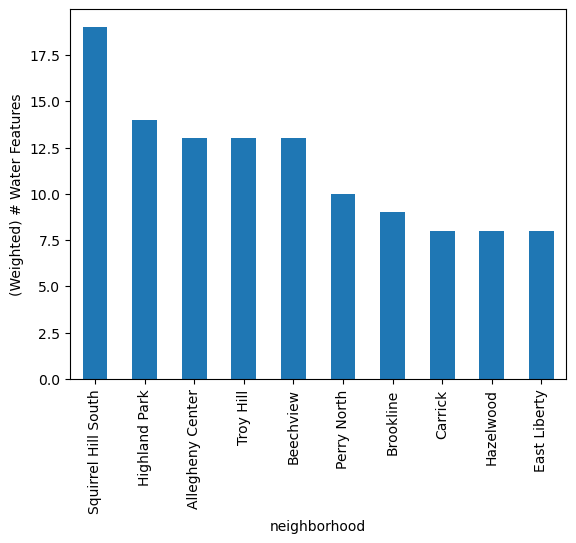

In [37]:
weighted_counts_w.head(10).plot(kind="bar", ylabel="(Weighted) # Water Features")

## "Best" Neighborhood!

Now that we have all of our information looking pretty, let's choose the best neighborhood!

### Candidates

Our candidates will be the top five neighborhoods from the "311" calls dataset analysis, from there we will narrow it down!

These candidates are:

 - South Side Slopes
 - Hazelwood
 - South Slide Flats
 - Garfield
 - Larimer

### With these, let's see if any of these appear in the green spaces data or water data!


In [41]:
candidates = [
    "South Side Slopes",
    "Hazelwood",
    "South Side Flats",
    "Garfield",
    "Larimer"
]

for candidate in candidates:
    if candidate in val_counts_g.keys() or candidate in weighted_counts_w.keys():
        candidates.remove(candidate)

candidates


['Hazelwood', 'Garfield']

### How do we narrow it down from here?

Great question!

The one thing that we are missing is "vibes," so, now that we have everything narrowed done with logic and code, I am going to look at photos of either one of them and then decide which one has more "CS vibes."

#### Vibes Check!

They both seem to have similar "vibes" from a quick preview at the images: I see cool art in images of both of them, so I beleive the deciding factor for a CS major would then be the name. A CS major would likely choose Garfield because it shares a name with a beloved comic.

## Conclusion

The Final Neighborhood is: GARFIELD!!!

The 311 data gave us 5 candidates that we would then want to look closer at, eliminating the other, until we got to our final decision.

This left us with South Side Slopes, Hazelwood, South Slide Flats, Garfield, and Larimer that needed to be narrowed down.

Because we want as little green space and water as possible, and because those datasets do not have every neighborhood, we were able to eliminate neighborhoods by them being in the other two datasets!

This left us with Hazelwood and Garfield!

The choice between the two of these was purely based on the name, we believed that a CS major would absolutely love to live in a neighborhood called Garfield more than one called Hazelwood!